# Titanic Survival Prediction — Classification Assignment

**Student practical workbook | Write your own Python code in the TODO cells below.**

**Goal:** Clean a real dataset, build 4 classification pipelines, compare them with cross-validation, tune at least 2 models, select a winner by training CV F1, and evaluate it once on a held-out test split.

- **Dataset:** [Titanic — Kaggle Competition](https://www.kaggle.com/competitions/titanic/data)
- **File to use:** `train.csv` only (contains `Survived`). Save it alongside this notebook.
- **Target:** `Survived` (`0` = did not survive, `1` = survived)
- **Primary model-selection score:** 5-fold cross-validated **F1** on the training set.

> **Important:** Kaggle's own `test.csv` has no outcome labels. Do not use it here. Generate your own test set from Kaggle `train.csv`.

## Student information

- **Student name / ID:** __________________________
- **Submission date:** _____________________________
- **Environment / Python version:** __________________

**How to complete:** Run each cell in order, add code beneath its `TODO` instructions, and write short Markdown explanations in the reflection cells. Keep outputs visible for submission. There is intentionally **no solution code**.

## 0. Import libraries and set up the environment

**Task:** Import `pandas`, `numpy`, plotting libraries, and all scikit-learn components required for splitting, preprocessing, modelling, tuning and evaluation. Keep one import per line where practical.

**Expected output:** No errors. Set a reproducible random seed (use `42`).

In [81]:
# TODO: Import pandas and numpy.
# TODO: Import matplotlib.pyplot and optionally seaborn.
# TODO: Import train_test_split, StratifiedKFold, cross_validate, GridSearchCV.
# TODO: Import SimpleImputer, OneHotEncoder, StandardScaler, ColumnTransformer, Pipeline.
# TODO: Import the four classifiers and evaluation metrics.
# TODO: Define RANDOM_STATE = 42 and DATA_PATH = "train.csv".

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 1. Load the Kaggle dataset

**Why:** Confirm that the correct labelled training file is available.

**Tasks:** Read `train.csv`, show its first 5 rows, print rows/columns, confirm that the `Survived` column exists.

**Expected output:** A preview of the dataset and its shape.

In [3]:
# TODO: Read DATA_PATH into df.
# TODO: Display df.head().
# TODO: Print df.shape and confirm 'Survived' is present.

df=pd.read_csv('train.csv')

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.shape

(891, 12)

In [7]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 2. Audit data types and missing values

**Why:** Cleaning decisions require evidence.

**Tasks:**
1. Inspect `df.info()` and `df.dtypes`.
2. Produce a table of missing values (count and percentage).
3. Show numeric summary statistics.
4. Count whole-row duplicates and repeated `PassengerId` values separately.
5. Check target distribution and inspect unusual `Age` / `Fare` values.

**Note:** Fractional `Age` can be valid for infants. Do not blindly convert it to integers.

In [8]:
# TODO: Print column data types and df.info().
# TODO: Calculate missing value counts and percentages per column.
# TODO: Display numeric descriptive statistics.
# TODO: Check df.duplicated() and df['PassengerId'].duplicated().
# TODO: Count each Survived class and investigate possible invalid values.
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
missing_value=df.isna().sum()
missing_prect = (((missing_value)/len(df))*100).round(2)

report = pd.DataFrame({'missing values':missing_value, 'missing %':missing_prect}, )
display(report.sort_values(by='missing values', ascending=False))


,missing values,missing %
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['PassengerId'].duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Name: PassengerId, Length: 891, dtype: bool

In [13]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [14]:
df['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [15]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [16]:
df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [17]:
df.describe(include='number')

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [18]:
df[df['Fare']==0]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
179,180,0,3,"Leonard, Mr. Lionel",male,36.0,0,0,LINE,0.0,NaN,S
263,264,0,1,"Harrison, Mr. William",male,40.0,0,0,112059,0.0,B94,S
271,272,1,3,"Tornquist, Mr. William Henry",male,25.0,0,0,LINE,0.0,NaN,S
277,278,0,2,"Parkes, Mr. Francis ""Frank""",male,NaN,0,0,239853,0.0,NaN,S
302,303,0,3,"Johnson, Mr. William Cahoone Jr",male,19.0,0,0,LINE,0.0,NaN,S
413,414,0,2,"Cunningham, Mr. Alfred Fleming",male,NaN,0,0,239853,0.0,NaN,S
466,467,0,2,"Campbell, Mr. William",male,NaN,0,0,239853,0.0,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0,NaN,S
597,598,0,3,"Johnson, Mr. Alfred",male,49.0,0,0,LINE,0.0,NaN,S
633,634,0,1,"Parr, Mr. William Henry Marsh",male,NaN,0,0,112052,0.0,NaN,S


In [19]:
df['Embarked'].isna().sum()

np.int64(2)

### Cleaning log — fill in after inspecting the data

| Issue found | Columns affected | Decision | Why? |
|---|---|---|---|
|Missing Values| `Cabin` | Drop/ Exclude from Baseline | More number of Missing Values |
|Missing Values | `Age` | Replace by median | Removes the Null Values |
|Drop Columns | `PassengerId`, `Name`, `Ticket`, `Cabin` | Simply drop the columns | Increases the noise in the dataset |
|Missing Values | `Embarked` | Replace by mode | Removes the Null Values |
|Not Categorical | `PClass` | One Hot Encoding | We will change it using OneHotEncodder |

**Important:** Keep learned imputation/statistical transformations inside training pipelines after the train/test split.

## 3. Exploratory Data Analysis (EDA)

**Tasks:** Create at least **three** labelled charts:
1. Class counts for `Survived`.
2. Survival rate by `Sex` and/or `Pclass`.
3. Distribution of `Age` or `Fare`, optionally split by outcome.

Include a title, axes labels and short interpretation for each chart. Avoid making causal claims.

<Axes: xlabel='Pclass'>

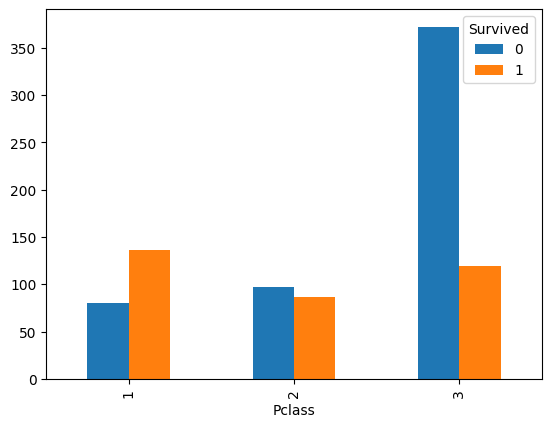

In [20]:
# TODO: Plot survival class counts.
# TODO: Plot survival rate by Sex and/or Pclass.
# TODO: Plot Age or Fare distribution.
# TODO: Add readable titles, labels and legends.

survived =df.groupby('Pclass')['Survived'].value_counts()
survived.unstack().plot(kind='bar')

<Axes: xlabel='Sex,Survived'>

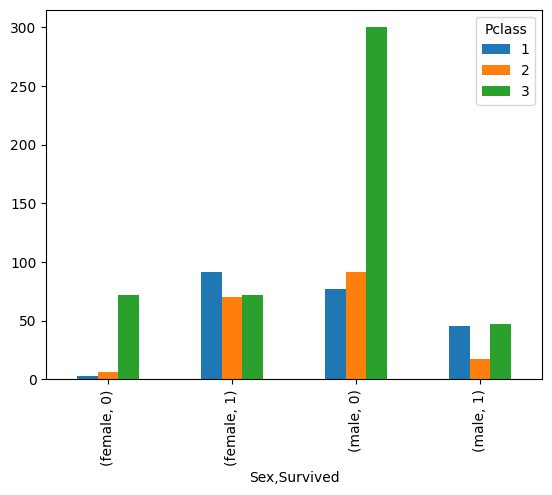

In [21]:
survived_sex =df.groupby('Sex')[['Survived', 'Pclass']].value_counts()
survived_sex.unstack().plot(kind='bar')

<Axes: ylabel='Frequency'>

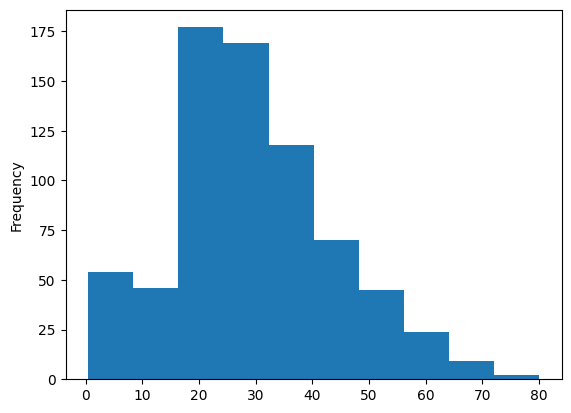

In [22]:
df['Age'].plot(kind='hist')

<Axes: >

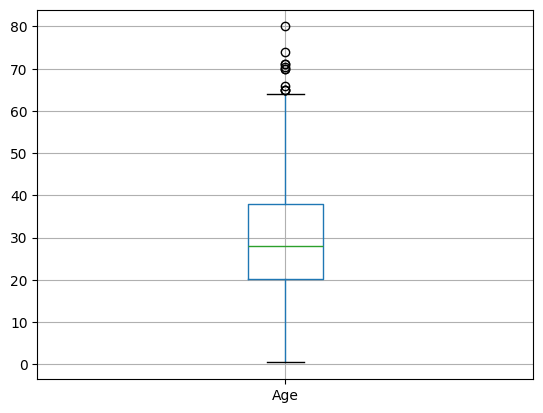

In [23]:
df.boxplot(column=['Age'])

<Axes: >

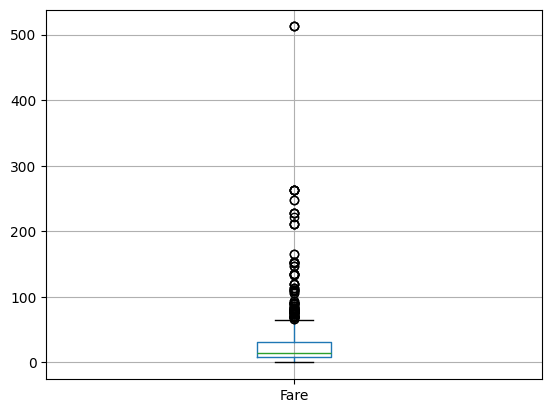

In [24]:
df.boxplot(column=['Fare'])

C:\Users\Shounak Kale\AppData\Local\Temp\ipykernel_34956\2308196224.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df, x='Age', hue='Survived', shade=True)


<Axes: xlabel='Age', ylabel='Density'>

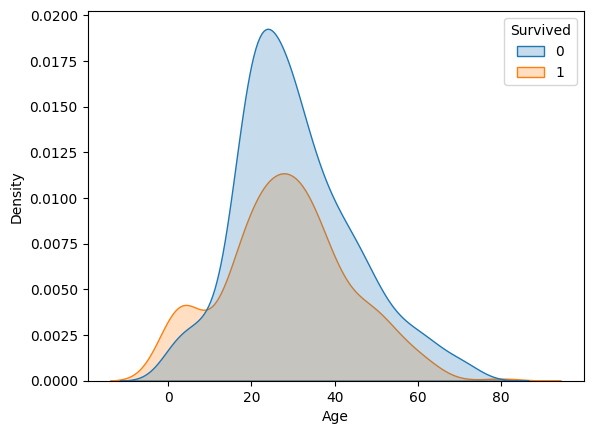

In [25]:
sns.kdeplot(data=df, x='Age', hue='Survived', shade=True)

C:\Users\Shounak Kale\AppData\Local\Temp\ipykernel_34956\1574131894.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df, x='Fare', hue='Survived', shade=True)


<Axes: xlabel='Fare', ylabel='Density'>

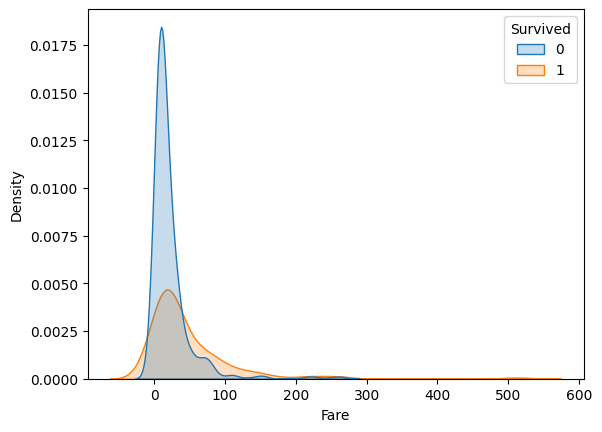

In [26]:
sns.kdeplot(data=df, x='Fare', hue='Survived', shade=True)

### EDA observations

1. **Observation 1:** More Passengers survived in Class 1 as compared to Class 3
2. **Observation 2:** The people who paid less fare were the ones that did not survive
3. **Observation 3:** Male ahve the highest number of deaths

In [27]:
clean_df = df.copy()
clean_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [28]:
clean_df=clean_df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
clean_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [29]:
clean_df['Age'] = clean_df['Age'].fillna(clean_df['Age'].median())
clean_df['Age'].isna().sum()

np.int64(0)

In [30]:
clean_df['Embarked'] = clean_df['Embarked'].fillna(clean_df['Embarked'].mode()[0])
clean_df['Embarked'].isna().sum()

np.int64(0)

In [31]:
clean_df.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [32]:
clean_df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 4. Define X and y, then perform train/test split

**Recommended features:**

- Numeric: `Age`, `Fare`, `SibSp`, `Parch`
- Categorical: `Sex`, `Embarked`, `Pclass`
- Target: `Survived`
- Exclude from baseline: `PassengerId`, `Name`, `Ticket`, `Cabin` (explain why).

**Tasks:** Set `X` and `y`, then perform a stratified **80% training / 20% test** split with `random_state=42`. Print shape and survival share for both splits.

> **No data leakage:** Do not fit any imputer, encoder, scaler, or model to all of `X` before splitting.

In [33]:
# TODO: Define numeric_features and categorical_features lists.
# TODO: Select X (only the recommended features) and y = Survived.
# TODO: Split with test_size=0.2, stratify=y, random_state=RANDOM_STATE.
# TODO: Print train/test shapes and target proportions.

numeric_features = ['Age', 'Fare', 'SibSp', 'Parch']
categorical_features = ['Sex', 'Embarked', 'Pclass']

features = numeric_features + categorical_features
features

['Age', 'Fare', 'SibSp', 'Parch', 'Sex', 'Embarked', 'Pclass']

In [34]:
X = clean_df[features].copy()
y = clean_df['Survived'].copy()

display(X.head())
display(y.head())

,Age,Fare,SibSp,Parch,Sex,Embarked,Pclass
0,22.0,7.2500,1,0,male,S,3
1,38.0,71.2833,1,0,female,C,1
2,26.0,7.9250,0,0,female,S,3
3,35.0,53.1000,1,0,female,S,1
4,35.0,8.0500,0,0,male,S,3


0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [36]:
print(f'Train Size: {X_train.shape}')
print(f'Test Size: {X_test.shape}')

Train Size: (712, 7)
Test Size: (179, 7)


## 5. Build leakage-safe preprocessing pipelines

**Why:** Training-fold statistics must not come from validation/test examples.

**Numeric branch:** median imputation → StandardScaler.

**Categorical branch:** most-frequent imputation → OneHotEncoder(handle_unknown='ignore').

**Combine:** ColumnTransformer with the two branches.

**Expected output:** Working `numeric_transformer`, `categorical_transformer`, and `preprocessor` objects. **Fit them only through each full model pipeline.**

In [37]:
# TODO: Create Pipeline for numeric columns (SimpleImputer + StandardScaler).
# TODO: Create Pipeline for categorical columns (SimpleImputer + OneHotEncoder).
# TODO: Combine these branches using ColumnTransformer.
# TODO: Explain why Pclass is treated as categorical.

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


### Explain data leakage (2–3 sentences)

**Your answer:** Data Leakage happens when the model trains on the Test Data alongwith the Training Data

## 6. Define four model pipelines

Create pipelines with `('preprocess', preprocessor)` followed by `('model', classifier)`.

**Required models:** Logistic Regression, KNN, Decision Tree, Random Forest.

Use `random_state=42` wherever the estimator supports it. For Logistic Regression, set a sufficiently large `max_iter` if convergence requires it.

**Expected output:** A dictionary named `models` mapping readable model names to complete sklearn Pipelines.

In [38]:
# TODO: Create Logistic Regression classifier and its Pipeline.
# TODO: Create K-Nearest Neighbors classifier and its Pipeline.
# TODO: Create Decision Tree classifier and its Pipeline.
# TODO: Create Random Forest classifier and its Pipeline.
# TODO: Store all four Pipelines in a dictionary named models.

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

lr_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=100, random_state=42))
])
lr_pipeline.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [39]:
y_pred_lr = lr_pipeline.predict(X_test)

In [40]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [41]:
print(accuracy_score(y_test, y_pred_lr))

0.8044692737430168


In [42]:
dt_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])
dt_pipeline.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [43]:
y_pred_dt = dt_pipeline.predict(X_test)

In [44]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



In [45]:
print(accuracy_score(y_test, y_pred_dt))

0.8156424581005587


In [46]:
rf_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])
rf_pipeline.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [47]:
y_pred_rf = rf_pipeline.predict(X_test)

In [48]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85       110
           1       0.79      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



In [49]:
print(accuracy_score(y_test, y_pred_rf))

0.8156424581005587


In [50]:
kn_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', KNeighborsClassifier())
])
kn_pipeline.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [51]:
y_pred_kn = kn_pipeline.predict(X_test)

In [52]:
print(classification_report(y_test, y_pred_kn))

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       110
           1       0.81      0.70      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



In [53]:
print(accuracy_score(y_test, y_pred_kn))

0.8212290502793296


In [54]:
models = {
    'Logistic Regression': lr_pipeline,
    'KNN': kn_pipeline,
    'Decision Tree': dt_pipeline,
    'Random Forest': rf_pipeline
}

for name, model in models.items():
    model.fit(X_train, y_train)
    score = model.score(X_test, y_test)

    print(f'{name} {score:.4f}')

Logistic Regression 0.8045
KNN 0.8212
Decision Tree 0.8156
Random Forest 0.8156


## 7. Cross-validation comparison — metrics for EVERY model

**Tasks:**
1. Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` on the **training split** only.
2. Use `cross_validate(...)` for all 4 pipelines with `scoring={'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1', 'roc_auc':'roc_auc'}`.
3. Save mean accuracy, precision, recall, F1 and ROC-AUC, plus F1 standard deviation.
4. Print a comparison DataFrame sorted by **mean CV F1**.

**Expected output:** A 4-row model-comparison table. Pipelines keep preprocessing inside each CV fold.

In [55]:
# TODO: Create the 5-fold StratifiedKFold object.
# TODO: Define scoring metrics.
# TODO: Loop through models and call cross_validate with X_train, y_train.
# TODO: Calculate each metric's mean and F1 standard deviation.
# TODO: Create and display a sorted comparison table.


In [56]:
scoring={
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

In [57]:
result = []

for name, model in models.items():
    cv_results = cross_validate(
        model,
        X_train, y_train,
        cv=StratifiedKFold(
            n_splits=5,
            random_state=42,
            shuffle=True
        ),
        scoring= scoring,
    )

    metrics_summary = {
        'Model': name,
        'Mean Accuracy': cv_results['test_accuracy'].mean(),
        'Mean Precision': cv_results['test_precision'].mean(),
        'Mean Recall': cv_results['test_recall'].mean(),
        'Mean F1': cv_results['test_f1'].mean(),
        'F1 Std': cv_results['test_f1'].std(),
        'Mean ROC-AUC': cv_results['test_roc_auc'].mean()
    }
    result.append(metrics_summary)

comparing_df = pd.DataFrame(result)

comparing_df

,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,F1 Std,Mean ROC-AUC
0,Logistic Regression,0.800581,0.762506,0.699731,0.728773,0.021660,0.852772
1,KNN,0.797754,0.772127,0.677576,0.720185,0.015143,0.841974
2,Decision Tree,0.772511,0.710376,0.688956,0.698628,0.021427,0.755651
3,Random Forest,0.800532,0.753664,0.717845,0.734431,0.023992,0.865480


### Baseline comparison — interpretation

- Model with highest mean CV F1: ___________________
- Model with lowest mean CV F1: ____________________
- Why might accuracy alone be insufficient? ___________________
- Models selected for tuning (at least two): ___________________

## 8. GridSearchCV — tune model A

**Tasks:** Choose one promising classifier, specify a small parameter grid using `model__parameter_name`, and run `GridSearchCV` with `scoring='f1'`, the same stratified CV, and `refit=True`.

**Suggested grids:**

| Model | Hyperparameter options |
|---|---|
| Logistic Regression | `model__C`: [0.1, 1, 10]; `model__class_weight`: [None, 'balanced'] |
| KNN | `model__n_neighbors`: [3, 5, 7, 11]; `model__weights`: ['uniform', 'distance'] |
| Decision Tree | `model__max_depth`: [3, 5, None]; `model__min_samples_leaf`: [1, 3, 5] |
| Random Forest | `model__n_estimators`: [100, 200]; `model__max_depth`: [None, 5, 10]; `model__min_samples_leaf`: [1, 3] |

**Expected output:** Model A best CV F1, best params, best fitted estimator.

In [58]:
# TODO: Choose model A from the models dictionary.
# TODO: Define param_grid_a with model__ prefixed keys.
# TODO: Create and fit GridSearchCV using X_train and y_train only.
# TODO: Print best_params_ and best_score_.

model = models['Logistic Regression']

param_grid = {
    'model__C': [0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    estimator= model,
    param_grid= param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)
grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__C': [0.1, 1, ...], 'model__class_weight': [None, 'balanced']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [59]:
print(f'Best CV F1 Score: {grid.best_score_:.4f}')

Best CV F1 Score: 0.7349


In [60]:
print(f'Best Hyperparameter: {grid.best_params_}')

Best Hyperparameter: {'model__C': 10, 'model__class_weight': 'balanced'}


## 9. GridSearchCV — tune model B

**Tasks:** Tune a **different classifier** using a sensible hyperparameter grid. Use the **same 5-fold CV** and F1 scoring.

**Expected output:** Model B best CV F1, best params, best fitted estimator.

In [61]:
# TODO: Choose a different model B.
# TODO: Define param_grid_b.
# TODO: Create and fit the second GridSearchCV on X_train and y_train.
# TODO: Print best_params_ and best_score_.

model = models['Random Forest']
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 5, 10],
    'model__min_samples_leaf': [1, 3] 
}

grid2 = GridSearchCV(
    estimator= model,
    param_grid= param_grid,
    cv=5,
    scoring='f1',
    n_jobs= -1
)

grid2.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 5, ...], 'model__min_samples_leaf': [1, 3], 'model__n_estimators': [100, 200]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [62]:
print(f'Best CV F1 Score: {grid2.best_score_:.4f}')

Best CV F1 Score: 0.7529


In [63]:
print(f'Best Hyperparameter: {grid2.best_params_}')

Best Hyperparameter: {'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}


In [64]:
model = models['Decision Tree']

param_grid={
    'model__max_depth': [3, 5, None],
    'model__min_samples_leaf': [1, 3, 5]
}

grid3 = GridSearchCV(
    estimator= model,
    param_grid= param_grid,
    cv=5,
    scoring= 'f1',
    n_jobs=-1
)

grid3.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 3, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [65]:
print(f'Best CV F1 Score: {grid3.best_score_:.4f}')

Best CV F1 Score: 0.7354


In [66]:
print(f'Best Hyperparameter: {grid3.best_params_}')

Best Hyperparameter: {'model__max_depth': None, 'model__min_samples_leaf': 5}


In [67]:
model = models['KNN']

param_grid = {
    'model__n_neighbors': [3, 5, 7, 11],
    'model__weights': ['uniform', 'distance']
}

grid4 = GridSearchCV(
    estimator= model,
    param_grid= param_grid,
    cv=5,
    scoring='f1',
    n_jobs= -1
)

grid4.fit(X_train, y_train)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'model__n_neighbors': [3, 5, ...], 'model__weights': ['uniform', 'distance']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [68]:
print(f'Best CV F1 Score: {grid4.best_score_:.4f}')

Best CV F1 Score: 0.7425


In [69]:
print(f'Best Hyperparameter: {grid4.best_params_}')

Best Hyperparameter: {'model__n_neighbors': 11, 'model__weights': 'uniform'}


## 10. Choose the final winner — WITHOUT viewing X_test

**Tasks:** Compare tuned best CV F1 against the baseline models' CV F1. Select one final model/pipeline; consider CV variability and model simplicity if scores are nearly tied. Write 2–4 sentences defending your choice.

**Do not evaluate on X_test until the final choice is documented.**

In [70]:
# TODO: Create one comparison summary for baseline and tuned candidates.
# TODO: Select the final fitted pipeline using only training CV results.
# TODO: Store it as final_model.
# TODO: Record model name and selected CV F1.

tuning_results = [
    {
        'Model': 'Logistic Regression', 
        'Mean CV F1': grid.best_score_, 
        'Estimator': grid.best_estimator_
    },
    {
        'Model': 'Random Forest', 
        'Mean CV F1': grid2.best_score_, 
        'Estimator': grid2.best_estimator_
    },
    {
        'Model': 'Decision Tree', 
        'Mean CV F1': grid3.best_score_, 
        'Estimator': grid3.best_estimator_
    },
    {
        'Model': 'KNN', 
        'Mean CV F1': grid4.best_score_, 
        'Estimator': grid4.best_estimator_
    }
]

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df[['Model', 'Mean CV F1']].sort_values(by='Mean CV F1', ascending=False).round(2))

,Model,Mean CV F1
1,Random Forest,0.75
3,KNN,0.74
2,Decision Tree,0.74
0,Logistic Regression,0.73


### Final selection rationale (complete BEFORE evaluating test data)

- **Selected model:** Random Forest
- **Mean training CV F1:** 0.75
- **Why it was selected:** The Mean CV F1 Score is greater as compared to others
- **Potential limitation:** __________________

## 11. Final evaluation on the untouched holdout test set

**Tasks:** Use `final_model` once on `X_test`. Predict class labels and (if available) positive-class probabilities. Report:

- Accuracy
- Precision (`Survived=1`)
- Recall (`Survived=1`)
- F1 (`Survived=1`)
- ROC-AUC (computed from scores/probabilities, **not** hard class labels)
- Classification report and confusion matrix

**Do not tune further after inspecting the test outcome.**

In [74]:
final_model = grid2.best_estimator_
winning_model_name = "Logistic Regression (Tuned)"
winning_cv_f1 = grid2.best_score_

y_pred = final_model.predict(X_test)

In [75]:
if hasattr(final_model, "predict_proba"):
    y_proba = final_model.predict_proba(X_test)[:, 1]
else:
    y_proba = final_model.decision_function(X_test)

In [76]:
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, y_proba)

In [77]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.92      0.86       110
           1       0.83      0.64      0.72        69

    accuracy                           0.81       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.81      0.81      0.80       179



In [78]:
confusion_matrix(y_test, y_pred)

array([[101,   9],
       [ 25,  44]])

In [79]:
final_metrics_df = pd.DataFrame([{
    'Test Accuracy': test_accuracy,
    'Test Precision': test_precision,
    'Test Recall': test_recall,
    'Test F1': test_f1,
    'Test ROC-AUC': test_roc_auc
}])

final_metrics_df

,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,0.810056,0.830189,0.637681,0.721311,0.838208


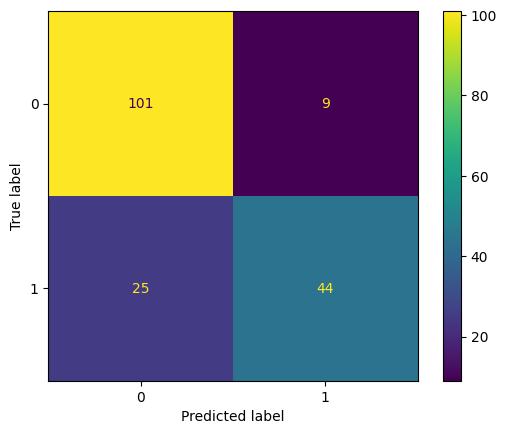

In [83]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['0', '1'])


## 12. Visualize errors and ROC curve

**Tasks:** Plot the confusion matrix and ROC curve. Clearly label the positive class (`Survived = 1`). Explain what a false positive and a false negative mean for this problem.

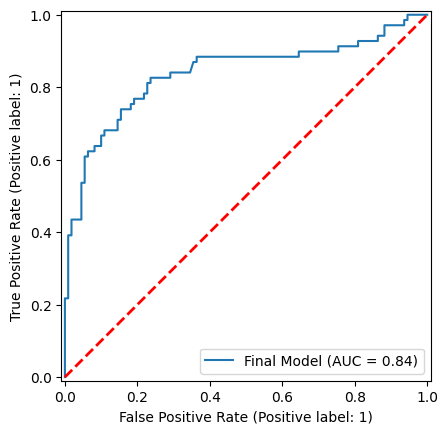

In [86]:
# TODO: Plot a labelled confusion matrix.
# TODO: Plot ROC curve using predicted probability/decision scores.
# TODO: Display and interpret ROC-AUC.

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test, 
    y_proba, 
    name="Final Model"
)

plt.plot([0, 1], [0, 1], color='red', linestyle='--', lw=2, label='Random Guess (AUC = 0.5)')

In [87]:
import pickle

In [ ]:
with open('titanic_model.pkl', 'wb') as file:
    pickle.dump(final_model, file)

In [89]:
with open('titanic_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

In [92]:
new_passenger= pd.DataFrame({
    'Pclass': [1],
    'Sex': ['female'],
    'Age': [25],
    'Fare': [7.75],
    'Embarked': ['S'],
    'SibSp': [0],
    'Parch': [0]
})

loaded_model.predict(new_passenger)

array([1])

### Error interpretation

- **False positive:** _______________________
- **False negative:** _______________________
- **Which error occurs more often?** _______________________
- **What does the ROC curve tell you?** _______________________

## 13. Final conclusion and limitations

Write a short Markdown summary that covers: dataset quality, 3 key EDA observations, four baseline CV results, both tuning results, chosen model, final holdout metrics, and three limitations.

**Reflection questions:**
1. Why must the split happen before fitting preprocessing?
2. Why should preprocessing be inside the CV pipeline?
3. How do precision and recall differ for surviving passengers?
4. Which hyperparameters did GridSearchCV favor, and why might that matter?
5. Did tuning improve cross-validated F1? Cite your scores.
6. Will this test result necessarily generalize to other passenger populations? Why/why not?

**Your answers:**

1. ____________________
2. ____________________
3. ____________________
4. ____________________
5. ____________________
6. ____________________

## 14. Submission checklist

- [ ] Dataset loaded and data types/missing values/duplicates inspected
- [ ] Cleaning log complete; no blind removal of valid fractional ages
- [ ] At least 3 EDA charts and 3 written observations
- [ ] Stratified 80/20 train/test split performed BEFORE learned preprocessing
- [ ] Numeric and categorical ColumnTransformer branches built
- [ ] Four complete model pipelines defined
- [ ] Comparison table: 5 CV metrics for all 4 models (+ F1 standard deviation)
- [ ] At least two GridSearchCV experiments completed
- [ ] Final model selected by CV **before** test evaluation
- [ ] Final holdout metrics, confusion matrix and ROC curve shown
- [ ] Reflection, conclusion, limitations and notebook outputs saved

**Submit:** The completed `.ipynb` file. The separate Word document contains the full assignment brief and marking rubric.